In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from datasets import load_dataset, Image

In [5]:
dataset = load_dataset("uoft-cs/cifar10")

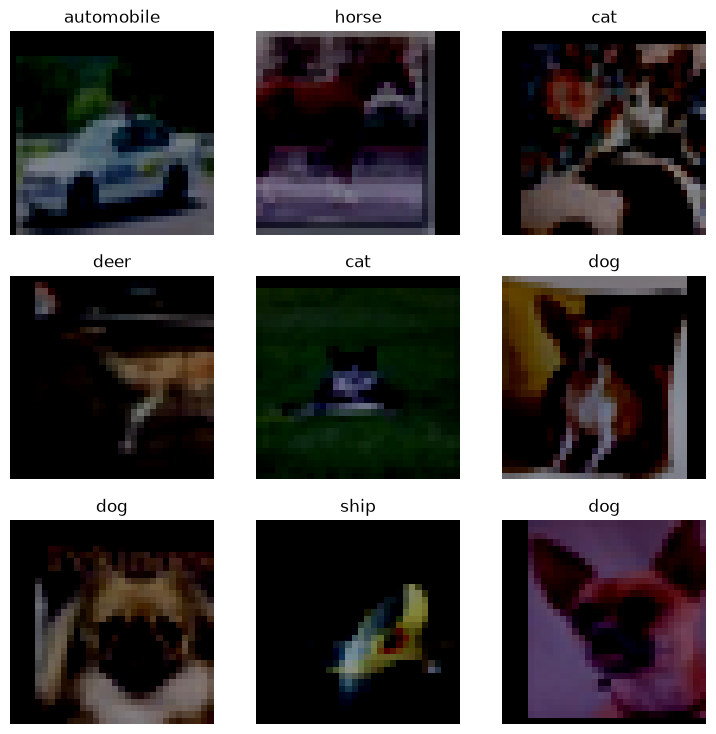

In [6]:
train_val = dataset["train"].train_test_split(test_size = 0.2, seed=111)

raw_train = train_val["train"]
val = train_val["test"]
test = dataset["test"]

# Apply data augmentation to training set
base_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# Calculate per-pixel mean following the paper
pixel_sum = torch.zeros(3, 32, 32)
count = 0

for batch in raw_train.iter(batch_size=256):
    imgs = torch.stack([base_transforms(img) for img in batch["img"]])
    pixel_sum += imgs.sum(dim=0)
    count += imgs.shape[0]

pixel_mean = pixel_sum / count

train_transforms_2 = v2.Compose([
    v2.ToImage(),
    v2.RandomHorizontalFlip(),
    v2.RandomCrop(32, padding=4),
    v2.ToDtype(torch.float32, scale=True),
    v2.Lambda(lambda img: img - pixel_mean)
])

eval_transforms = v2.Compose([
    *base_transforms.transforms,
    v2.Lambda(lambda examples: examples - pixel_mean)
])

# Apply Necessary Transforms (including normalization haha)
def apply_train_transforms_2(examples):
    examples["img"] = [train_transforms_2(img) for img in examples["img"]]
    return examples

def apply_eval_transforms(examples):
    examples["img"] = [eval_transforms(img) for img in examples["img"]]
    return examples

train = raw_train.with_transform(apply_train_transforms_2)
val = val.with_transform(apply_eval_transforms)
test = test.with_transform(apply_eval_transforms)

# HuggingFace datasets preserve the class-index order btw btw btw btw btw
labels_map = dict(enumerate(train.features["label"].names))
classes = len(labels_map)

figure = plt.figure(figsize=(9, 9))
cols, rows = 3, 3

for i in range(1, cols * rows + 1):
    idx = i - 1
    img = train[i]["img"]
    label = train[i]["label"]
    figure.add_subplot(rows, cols, i),
    plt.title(labels_map[label]),
    plt.axis("off"),
    plt.imshow(img.permute(1, 2, 0).clamp(min=0, max=1)),

plt.show()

In [7]:
torch.manual_seed(42)

In [8]:
# From the python module...
from residual_connections import ResNet

In [9]:
batch_size = 64

train_dataloader = DataLoader(train, batch_size=batch_size)
val_dataloader = DataLoader(val, batch_size=batch_size)
test_dataloader = DataLoader(test, batch_size=batch_size)

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

Using device: cpu


In [11]:
criterion = nn.CrossEntropyLoss()
model = ResNet().to(device)
optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=0.0001
)

In [ ]:
# data augmentation helps model generalize 
# despite this, only train for 15 epochs because i have an rx580 lol
num_epochs = 15

lr_milestones = {32_000, 48_000}

it = 0
history = {
    "train_loss": [], "train_acc": [],
    "valid_loss": [], "valid_acc": [],
}

for epoch in range(num_epochs):
    # --- Training ---
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch in train_dataloader:
        images = batch["img"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

        it += 1
        if it in lr_milestones:
            for group in optimizer.param_groups:
                group["lr"] /= 10
            print(f"  [iter {it:,}] lr -> {optimizer.param_groups[0]['lr']:g}")

    train_loss /= train_total
    train_acc = train_correct / train_total

    # --- Validation ---
    model.eval()
    valid_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in val_dataloader:
            images = batch["img"].to(device)
            labels = batch["label"].to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    valid_loss /= total
    valid_acc = correct / total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["valid_loss"].append(valid_loss)
    history["valid_acc"].append(valid_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2%} | "
        f"Valid Loss: {valid_loss:.4f} | Valid Acc: {valid_acc:.2%}"
    )

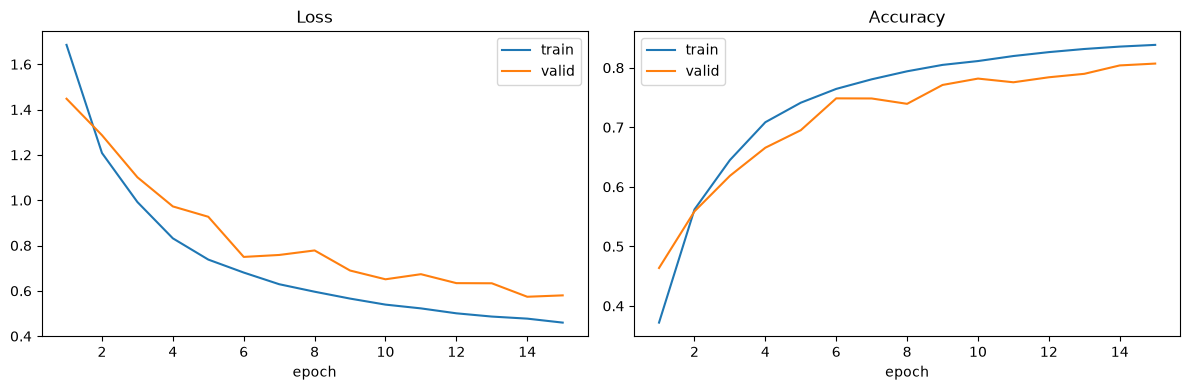

In [13]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs, history["train_loss"], label="train")
ax_loss.plot(epochs, history["valid_loss"], label="valid")
ax_loss.set_title("Loss")
ax_loss.set_xlabel("epoch")
ax_loss.legend()

ax_acc.plot(epochs, history["train_acc"], label="train")
ax_acc.plot(epochs, history["valid_acc"], label="valid")
ax_acc.set_title("Accuracy")
ax_acc.set_xlabel("epoch")
ax_acc.legend()

plt.tight_layout()
plt.show()

In [14]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for batch in test_dataloader:
        images = batch["img"].to(device)
        labels = batch["label"].to(device)

        outputs = model(images)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {correct / total:.2%}")

Test accuracy: 78.97%
